# 03 - Results

Results of final evaluation runs, read back from MLflow. All final runs use same code and same sampled pages (seed 0), hence numbers are directly comparable.

Sections:

1. Session context - what borrowing from same-session photos buys
2. Template against LLM writer
3. Validator fix for scene words - before and after
4. Hand review against LLM judge
5. Failure cases
6. Repetition when a folder is laid out as a book
7. Sensitivity and uncertainty - how much results depend on settings, and how sure they are

In [77]:
import json
import os
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from omegaconf import OmegaConf
from PIL import Image, ImageOps

from captioner import TemplateWriter, caption_page
from captioner.config import load_config
from captioner.evaluation.metrics import page_record, summarise
from captioner.evaluation.sampling import dedupe, sample_pages
from captioner.photo import photos_in

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "sqlite:///mlflow.db"))

# Final runs start from here
FINAL_FROM = pd.Timestamp("2026-10-31 18:39", tz="UTC")

# LLM run rated manually before scene word fix
REVIEW_RUN = "181aa8962a0746869bfef67eaac47662"

TEMPLATE, LLM, PAGE_ONLY = "#2a78d6", "#eb6834", "#9a9a9a"
LABELLED = ["day-at-beach", "garden-birthday-party", "skiing-holiday"]

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
        "figure.dpi": 110,
    }
)
pd.set_option("display.precision", 3)

## Runs

Every eval run is in MLflow with settings, metrics and per-page outputs. `pick` takes latest final run for a given set of settings.

In [78]:
runs = mlflow.search_runs(experiment_names=["caption-evaluation"], order_by=["start_time DESC"])
runs["writer"] = runs["params.writer"].str.split(":").str[0]
runs["judged"] = runs["params.judge"] != "off"


def pick(
    writer: str, context: bool = True, mode: str = "random", judged: bool = False
) -> pd.Series:
    match = runs[
        (runs["writer"] == writer)
        & (runs["params.use_context"] == str(context))
        & (runs["params.mode"] == mode)
        & (runs["judged"] == judged)
        & (runs["start_time"] >= FINAL_FROM)
    ]
    return match.iloc[0]


def table(selected: dict[str, pd.Series], keys: list[str], prefix: str = "all") -> pd.DataFrame:
    return pd.DataFrame(
        {
            name: {k: run.get(f"metrics.{prefix}/{k}") for k in keys}
            for name, run in selected.items()
        }
    ).T


final = {
    "template, page only": pick("template", context=False),
    "template, context": pick("template"),
    "template, context, consecutive": pick("template", mode="consecutive"),
    "llm, page only": pick("llm", context=False),
    "llm, context": pick("llm"),
    "llm, context, consecutive": pick("llm", mode="consecutive"),
    "template, judged": pick("template", judged=True),
    "llm, judged": pick("llm", judged=True),
}
pd.DataFrame(
    {
        name: {
            "run": run["run_id"][:8],
            "started": run["start_time"].strftime("%H:%M"),
            "pages": int(run["metrics.all/pages"]),
        }
        for name, run in final.items()
    }
).T

,run,started,pages
"template, page only",a3fb98c5,18:40,360
"template, context",01350a1f,18:40,360
"template, context, consecutive",e769769f,18:41,360
"llm, page only",2359fd64,18:41,360
"llm, context",7d7513c6,18:40,360
"llm, context, consecutive",c27b91f7,18:41,360
"template, judged",c4a800cb,18:48,360
"llm, judged",96bc0153,18:55,360


Each run captions 90 pages per folder after near-duplicate removal. Four folders, hence 360 pages per run. Three folders have an expected occasion. Grandkids folder has none, so it counts towards grounding and variety but not accuracy.

## 1. Session context

Pages captioned on their own photos only, against pages that may borrow occasion from other photos taken within 6 hours and 25 km.

In [79]:
keys = ["accuracy", "wrong", "abstained", "occasion_borrowed", "years_grounded"]
table(
    {
        k: final[k]
        for k in ["template, page only", "template, context", "template, context, consecutive"]
    },
    keys,
)

,accuracy,wrong,abstained,occasion_borrowed,years_grounded
"template, page only",0.585,0.022,0.393,0.000,1.0
"template, context",0.985,0.004,0.011,0.372,1.0
"template, context, consecutive",0.982,0.004,0.015,0.339,1.0


Context lifts accuracy from 0.59 to 0.98, mainly by cutting abstentions from 39% to about 1%. Wrong occasions also drop, from 2.2% to 0.4%, since borrowing only happens when setting is compatible and nothing on the page blocks it. Consecutive pages - closer to a real book - behave the same as random ones. Years are grounded in EXIF on every page. Writers share the same facts, hence LLM rows (section 2) have identical accuracy.

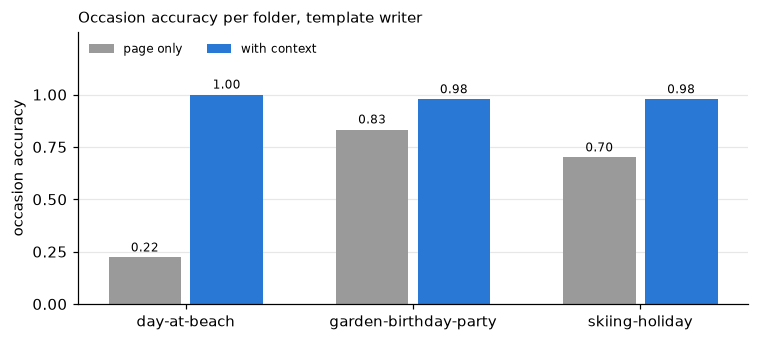

In [80]:
page_only, context = final["template, page only"], final["template, context"]
acc = pd.DataFrame(
    {
        "page only": [page_only[f"metrics.{f}/accuracy"] for f in LABELLED],
        "with context": [context[f"metrics.{f}/accuracy"] for f in LABELLED],
    },
    index=LABELLED,
)

fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.36
x = range(len(acc))
for offset, (name, colour) in zip(
    (-width / 2, width / 2), [("page only", PAGE_ONLY), ("with context", TEMPLATE)]
):
    bars = ax.bar([i + offset for i in x], acc[name], width - 0.04, color=colour, label=name)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
ax.set_xticks(list(x), acc.index)
ax.set_ylim(0, 1.3)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_ylabel("occasion accuracy")
ax.set_title("Occasion accuracy per folder, template writer", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left", ncols=2, fontsize=8)
plt.tight_layout()

Gain largest for the beach folder (0.22 to 1.00), where most photos are close ups of people with little beach in frame.
Party and ski pages carry more of their occasion on their own, yet still gain.

## 2. Template against LLM writer

Same facts, two writers. Judge and CLIP scores come from the judged runs, variety from the sweep.

In [81]:
keys = [
    "accuracy",
    "writer_rejected",
    "distinct_captions",
    "mean_length",
    "judge_faithful",
    "judge_specific",
    "judge_natural",
    "judge_unsupported",
    "clip",
    "clip_gain",
]
table({"template": final["template, judged"], "llm": final["llm, judged"]}, keys)

,accuracy,writer_rejected,distinct_captions,mean_length,judge_faithful,judge_specific,judge_natural,judge_unsupported,clip,clip_gain
template,0.985,0.000,0.039,41.53,4.803,5.0,4.947,0.042,0.257,0.000
llm,0.985,0.075,0.153,35.67,4.769,5.0,4.978,0.075,0.249,-0.009


In [82]:
keys = ["distinct_captions", "writer_rejected"]
table(
    {
        k: final[k]
        for k in [
            "template, context",
            "llm, context",
            "template, context, consecutive",
            "llm, context, consecutive",
        ]
    },
    keys,
)

,distinct_captions,writer_rejected
"template, context",0.039,0.000
"llm, context",0.131,0.064
"template, context, consecutive",0.033,0.000
"llm, context, consecutive",0.125,0.075


LLM gives approx 4 times the variety of the template, at almost equal faithfulness by the judge (4.77 against 4.80). Judge scores for specific and natural sit at the ceiling for both writers (5.0 and about 4.95), hence they don't separate the writers. Only faithfulness is informative. Validator rejects 7.5% of LLM captions, which fall back to the template. CLIP sees no real difference and gain is within noise, as expected for captions built from the same facts. LLM variety moves a little between runs since sampling isn't deterministic.

What the validator rejects in the final LLM run - every rejection is now a scene word:

In [83]:
reasons_path = mlflow.artifacts.download_artifacts(
    run_id=final["llm, judged"]["run_id"], artifact_path="rejection_reasons.json"
)
pd.Series(json.loads(Path(reasons_path).read_text()), name="pages").head(8).to_frame()

,pages
"<word> describes the scene, which the facts don't",27


## 3. Validator fix for scene words

First version of the validator only checked capitalised words, hence "in the snow" and "in the dark" passed. Fix added season, weather, time of day, rooms and scenery, each allowed only when facts or labels support it. Both runs below are LLM runs with the judge, on 10 pages per size, before and after the fix.

In [84]:
before = runs[runs["run_id"] == REVIEW_RUN].iloc[0]
after = runs[
    (runs["writer"] == "llm")
    & runs["judged"]
    & (runs["params.pages_per_size"] == "10")
    & (runs["start_time"] > before["start_time"])
    & (runs["start_time"] < FINAL_FROM)
].iloc[0]
keys = ["writer_rejected", "distinct_captions", "judge_faithful", "judge_unsupported"]
table({"before fix": before, "after fix": after}, keys)

,writer_rejected,distinct_captions,judge_faithful,judge_unsupported
before fix,0.00,0.342,4.642,0.133
after fix,0.05,0.250,4.750,0.075


Fix raised judge faithfulness from 4.64 to 4.75 and rejected about 5% of LLM captions. Cost is some variety, since rejected captions become template captions.

## 4. Hand review against LLM judge

32 pages from the pre-fix run, sampled evenly across folders, rated 1 to 5 for faithfulness (is everything true of the photos) and naturalness (would you print it in your own book). Same pages carry the judge's scores from that run, hence these can be compared directly.

In [85]:
review = pd.read_csv(ROOT / "outputs" / "review" / REVIEW_RUN / "review.csv")
pages_path = mlflow.artifacts.download_artifacts(run_id=REVIEW_RUN, artifact_path="pages.jsonl")
pages = pd.DataFrame(
    [json.loads(line) for line in Path(pages_path).read_text().splitlines() if line]
)
pages["key"] = pages["images"].str.join(";")
judge = pd.json_normalize(pages["judge"]).add_prefix("judge_").set_index(pages["key"])
both = review.join(judge[~judge.index.duplicated()], on="images")

summary = both.groupby("folder")[["faithful", "judge_faithful", "natural", "judge_natural"]].mean()
summary.loc["all"] = both[["faithful", "judge_faithful", "natural", "judge_natural"]].mean()
summary

,faithful,judge_faithful,natural,judge_natural
folder,,,,
day-at-beach,4.250,5.000,4.000,5.000
garden-birthday-party,4.125,3.875,3.500,4.625
skiing-holiday,4.250,4.625,3.375,5.000
summer-with-grandkids,3.375,5.000,3.375,5.000
all,4.000,4.625,3.562,4.906


In [86]:
rank = both[["faithful", "judge_faithful", "natural", "judge_natural"]].rank()
print(f"rank correlation, faithful: {rank['faithful'].corr(rank['judge_faithful']):.2f}")
print(f"rank correlation, natural:  {rank['natural'].corr(rank['judge_natural']):.2f}")
pd.crosstab(
    both["faithful"] >= 4, both["judge_faithful"] >= 4, rownames=["hand 4+"], colnames=["judge 4+"]
)

rank correlation, faithful: 0.00
rank correlation, natural:  0.29


judge 4+,False,True
hand 4+,,
False,1,9
True,3,19


Pages where hand and judge disagree most on faithfulness:

In [87]:
both["gap"] = both["judge_faithful"] - both["faithful"]
both.sort_values("gap", ascending=False)[
    ["id", "caption", "faithful", "judge_faithful", "judge_unsupported"]
].head(6)

,id,caption,faithful,judge_faithful,judge_unsupported
12,13,7th February 2019 – Birthday party in the snow,1,5,[]
31,32,13th–14th September 2018 – Baking treats indoors,2,5,[]
27,28,14th September 2018 – Baking treats at home,2,5,[]
18,19,"Skiing with kids in Yuzawa, February 2020",2,5,[]
29,30,13th–14th September 2018 – Autumn baking,3,5,[]
28,29,14th September 2018 – Baking in the autumn,3,5,[]


Judge is more lenient than a person - 4.6 against 4.0 for faithfulness, 4.9 against 3.6 for naturalness. Worse, it doesn't rank pages the way a person does (rank correlation 0.00 for faithfulness). Judge sees facts and label names but not the photos, hence it can't tell that "in the snow" is wrong for a sunny garden, nor that labelled kids are adults, nor that a child on the sofa isn't baking. Judge is useful for catching words with no support in the facts, and for comparing runs at scale. Hand review stays the reference for whether a caption is true of the photos.

## 5. Failure cases

Four pages from the hand review, one per kind of failure.

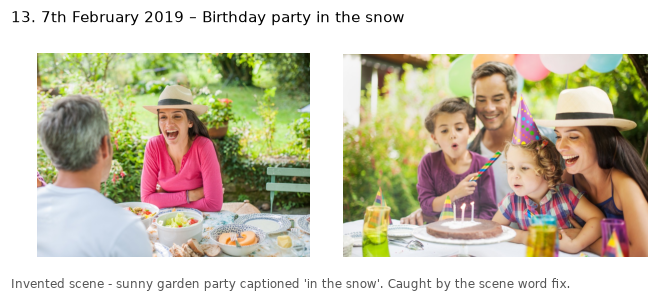

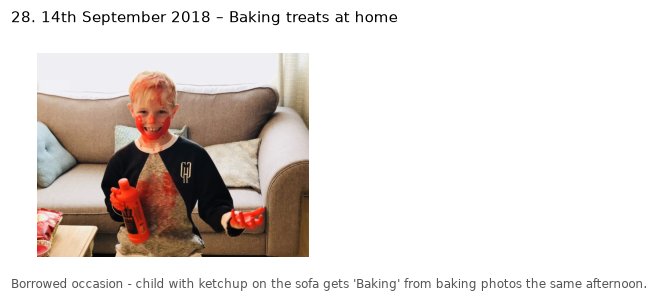

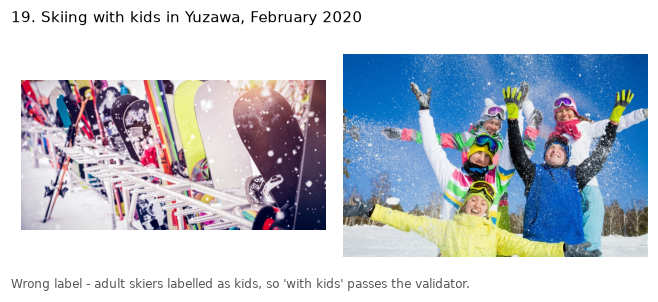

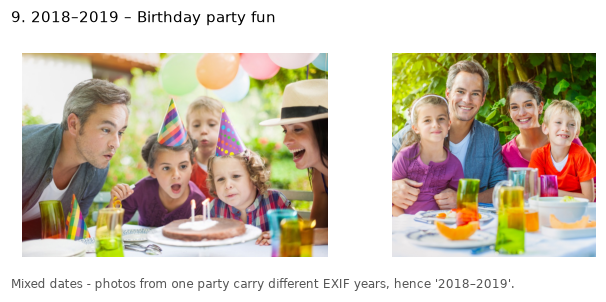

In [88]:
cases = {
    13: "Invented scene - sunny garden party captioned 'in the snow'. Caught by the scene word fix.",
    28: "Borrowed occasion - child with ketchup on the sofa gets 'Baking' from baking photos the same afternoon.",
    19: "Wrong label - adult skiers labelled as kids, so 'with kids' passes the validator.",
    9: "Mixed dates - photos from one party carry different EXIF years, hence '2018–2019'.",
}


def show(case_id: int, note: str) -> None:
    page = review.set_index("id").loc[case_id]
    images = page["images"].split(";")
    fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 2.6), squeeze=False)
    for ax, path in zip(axes[0], images):
        with Image.open(path) as im:
            ax.imshow(ImageOps.exif_transpose(im))
        ax.axis("off")
    fig.suptitle(f"{case_id}. {page['caption']}", x=0.01, ha="left", fontsize=10)
    fig.text(0.01, 0.01, note, fontsize=8, color="#555")
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()


for case_id, note in cases.items():
    show(case_id, note)

Each points to a different fix:

- Invented scene details - scene word list in the validator (done), plus a stricter prompt.
- Borrowed occasions - require some page evidence before borrowing, not only compatible setting.
- Wrong labels - can't be fixed downstream. Needs a better vision step, or a vision model checking people words.
- Mixed dates - use majority date of the page rather than the full range, and flag the page.

## 6. Repetition when laid out as a book

Each folder laid out as a book - photos in time order, 2 per page, whole folder as album. Made with `make outputs`.

In [89]:
def book(writer: str) -> pd.DataFrame:
    path = ROOT / "outputs" / "examples" / writer / "captions.jsonl"
    rows = pd.DataFrame([json.loads(line) for line in path.read_text().splitlines() if line])
    return rows.groupby("folder")["caption"].agg(
        pages="size",
        distinct="nunique",
        most_common_share=lambda c: c.value_counts(normalize=True).iloc[0],
    )


books = pd.concat({"template": book("template"), "llm": book("llm")}, axis=1)
books

template                              llm           \
                         pages distinct most_common_share pages distinct   
folder                                                                     
day-at-beach                30        1             1.000    30       13   
garden-birthday-party       34        3             0.941    34        5   
skiing-holiday              34        3             0.882    34        6   
summer-with-grandkids       59        4             0.559    59        8   

                                         
                      most_common_share  
folder                                   
day-at-beach                      0.367  
garden-birthday-party             0.588  
skiing-holiday                    0.765  
summer-with-grandkids             0.559

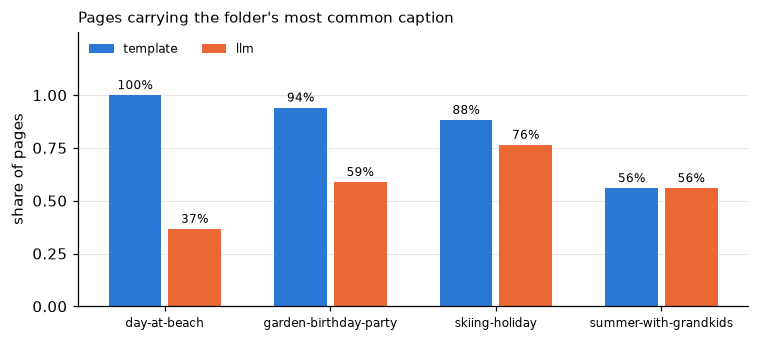

In [90]:
share = pd.DataFrame({w: books[(w, "most_common_share")] for w in ["template", "llm"]})

fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.36
x = range(len(share))
for offset, (name, colour) in zip((-width / 2, width / 2), [("template", TEMPLATE), ("llm", LLM)]):
    bars = ax.bar([i + offset for i in x], share[name], width - 0.04, color=colour, label=name)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in share[name]], padding=2, fontsize=8)
ax.set_xticks(list(x), share.index, fontsize=8)
ax.set_ylim(0, 1.3)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_ylabel("share of pages")
ax.set_title("Pages carrying the folder's most common caption", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left", ncols=2, fontsize=8)
plt.tight_layout()

Template repeats one caption on most pages of a folder - each one correct, but the book reads badly. LLM helps unevenly - most on the beach folder (37% of pages share the top caption, against 100%), less on party and ski (59% and 77%), not at all on grandkids (56% for both), since pages with no occasion skip the model and use the template. Fix belongs above the page - caption per section of the book (one title for the ski trip), with shorter or no captions on pages within it.

## 7. Sensitivity and uncertainty

Settings in `occasions.toml` were set by reasoning about the labels, not tuned on these photos - there are too few to tune on without overfitting. Question here is whether results hang on knife-edge choices. Each setting is varied on its own, holding the rest at default, on the same pages as the final runs. Template writer only, since writer doesn't change occasion. Resolution is coarse - one wrong page out of 270 labelled pages is 0.4%.

Accuracy alone misses one risk. Labelled folders are each one event, hence borrowing across a whole day can't go wrong there. Grandkids folder has several activities over a weekend, so share of its pages that borrow an occasion is tracked as a proxy for over-reach.

In [91]:
EXPECTED = OmegaConf.to_container(OmegaConf.load(ROOT / "configs" / "evaluate.yaml").expected)
BASE = load_config()
WRITER = TemplateWriter()
UNLABELLED = "summer-with-grandkids"

albums = {f: photos_in(ROOT / "data" / f) for f in sorted(EXPECTED)}
pages = {
    f: sample_pages(dedupe(album), (1, 2, 3), 30, "random", seed)
    for seed, (f, album) in enumerate(albums.items())
}


def score(**settings: float) -> dict[str, float]:
    config = replace(BASE, settings=replace(BASE.settings, **settings))
    records = [
        page_record(caption_page(page, albums[f], WRITER, config=config), f, EXPECTED[f])
        for f, folder_pages in pages.items()
        for page in folder_pages
    ]
    m = summarise(records)
    return {
        "accuracy": m["all/accuracy"],
        "wrong_pages": round(m["all/wrong"] * 270),
        "abstained": m["all/abstained"],
        "grandkids_borrowed": m[f"{UNLABELLED}/occasion_borrowed"],
    }


pd.DataFrame({"defaults": score()}).T

,accuracy,wrong_pages,abstained,grandkids_borrowed
defaults,0.985,1.0,0.011,0.289


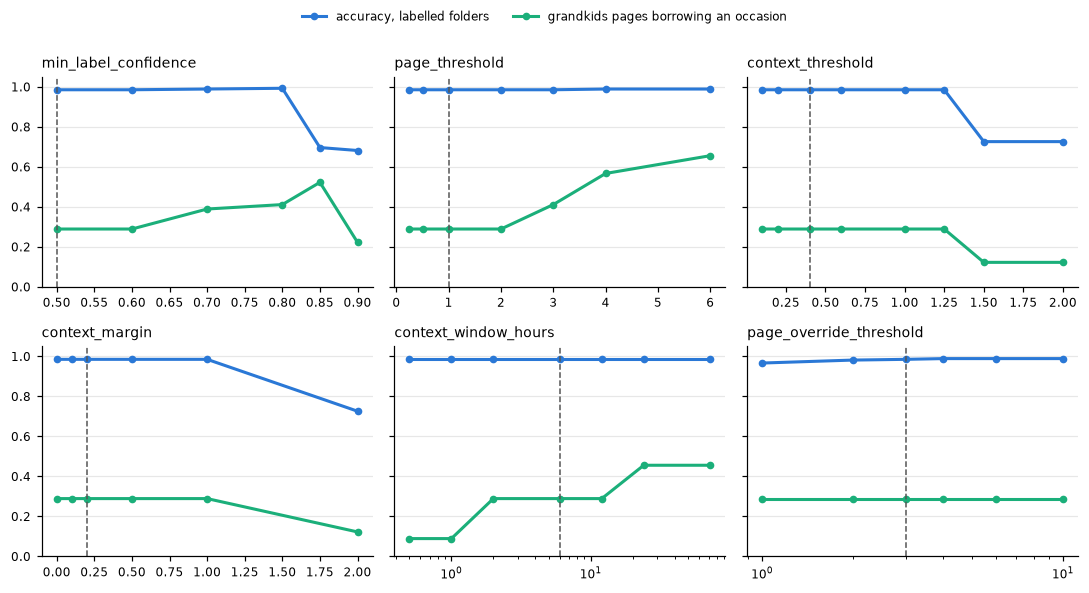

In [92]:
SWEEPS = {
    "min_label_confidence": [0.5, 0.6, 0.7, 0.8, 0.85, 0.9],
    "page_threshold": [0.25, 0.5, 1.0, 2.0, 3.0, 4.0, 6.0],
    "context_threshold": [0.1, 0.2, 0.4, 0.6, 1.0, 1.25, 1.5, 2.0],
    "context_margin": [0.0, 0.1, 0.2, 0.5, 1.0, 2.0],
    "context_window_hours": [0.5, 1, 2, 6, 12, 24, 72],
    "page_override_threshold": [1.0, 2.0, 3.0, 4.0, 6.0, 10.0],
}
sweep = pd.DataFrame(
    [
        {"setting": name, "value": v} | score(**{name: v})
        for name, values in SWEEPS.items()
        for v in values
    ]
)

fig, axes = plt.subplots(2, 3, figsize=(10, 5.4), sharey=True)
for ax, (name, group) in zip(axes.flat, sweep.groupby("setting", sort=False)):
    ax.plot(
        group["value"],
        group["accuracy"],
        marker="o",
        ms=4,
        lw=2,
        color=TEMPLATE,
        label="accuracy, labelled folders",
    )
    ax.plot(
        group["value"],
        group["grandkids_borrowed"],
        marker="o",
        ms=4,
        lw=2,
        color="#1baf7a",
        label="grandkids pages borrowing an occasion",
    )
    ax.axvline(getattr(BASE.settings, name), color="#555", lw=1, ls="--")
    ax.set_title(name, loc="left", fontsize=9)
    ax.tick_params(labelsize=8)
    if name in ("context_window_hours", "page_override_threshold"):
        ax.set_xscale("log")
axes[0, 0].set_ylim(0, 1.05)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncols=2, frameon=False, fontsize=8)
plt.tight_layout(rect=(0, 0, 1, 0.94))

In [93]:
sweep.set_index(["setting", "value"])[["accuracy", "wrong_pages", "grandkids_borrowed"]]

accuracy  wrong_pages  grandkids_borrowed
setting                 value                                           
min_label_confidence    0.50      0.985            1               0.289
                        0.60      0.985            1               0.289
                        0.70      0.989            0               0.389
                        0.80      0.993            0               0.411
                        0.85      0.696            0               0.522
                        0.90      0.681            0               0.222
page_threshold          0.25      0.985            1               0.289
                        0.50      0.985            1               0.289
                        1.00      0.985            1               0.289
                        2.00      0.985            1               0.289
                        3.00      0.985            1               0.411
                        4.00      0.989            0               0.567
                        6.00      0.989            0               0.656
context_threshold       0.10      0.985            1               0.289
                        0.20      0.985            1               0.289
                        0.40      0.985            1               0.289
                        0.60      0.985            1               0.289
                        1.00      0.985            1               0.289
                        1.25      0.985            1               0.289
                        1.50      0.726            1               0.122
                        2.00      0.726            1               0.122
context_margin          0.00      0.985            1               0.289
                        0.10      0.985            1               0.289
                        0.20      0.985            1               0.289
                        0.50      0.985            1               0.289
                        1.00      0.985            1               0.289
                        2.00      0.726            1               0.122
context_window_hours    0.50      0.985            1               0.089
                        1.00      0.985            1               0.089
                        2.00      0.985            1               0.289
                        6.00      0.985            1               0.289
                        12.00     0.985            1               0.289
                        24.00     0.985            1               0.456
                        72.00     0.985            1               0.456
page_override_threshold 1.00      0.967            6               0.289
                        2.00      0.982            2               0.289
                        3.00      0.985            1               0.289
                        4.00      0.989            0               0.289
                        6.00      0.989            0               0.289
                        10.00     0.989            0               0.289

Defaults sit on a wide plateau. Accuracy stays at 0.985 for page_threshold from 0.25 to 6, context_threshold up to 1.25, context_margin up to 1 and min_label_confidence up to 0.8. Cliffs are far from defaults - context_threshold 1.5 or margin 2 drop accuracy to 0.73, and min_label_confidence 0.85 or more to about 0.69. Hence results don't hang on a knife-edge choice.

Session window is where accuracy can't see the risk. Accuracy is flat from half an hour to three days, since each labelled folder is one event. But share of grandkids pages borrowing an occasion goes from 9% (1 hour or less) to 29% (2 to 12 hours) to 46% (a day or more) - most of that extra borrowing is the "Baking" over-reach seen in the failure cases. 6 hours sits mid-plateau. Shorter windows trade accuracy on weak pages for less over-reach, and need data with mixed sessions to set properly.

page_override_threshold of 4 or more removes the single wrong page. Not changed, since picking it after seeing this data would be tuning on the test set.

Accuracy also depends on how many photos are on a page:

In [94]:
def pages_of(run: pd.Series) -> pd.DataFrame:
    path = mlflow.artifacts.download_artifacts(run_id=run["run_id"], artifact_path="pages.jsonl")
    return pd.DataFrame([json.loads(line) for line in Path(path).read_text().splitlines() if line])


page_only, context = pages_of(final["template, page only"]), pages_of(final["template, context"])
labelled = context["expected"].notna()
by_size = pd.DataFrame(
    {
        "page only": (page_only[labelled]["outcome"] == "right")
        .groupby(page_only["n_photos"])
        .mean(),
        "with context": (context[labelled]["outcome"] == "right")
        .groupby(context["n_photos"])
        .mean(),
    }
).rename_axis("photos on page")
by_size["gain"] = by_size["with context"] - by_size["page only"]
by_size

,page only,with context,gain
photos on page,,,
1,0.378,0.956,0.578
2,0.633,1.000,0.367
3,0.744,1.000,0.256


Single-photo pages gain most from context - 0.38 to 0.96 - since one photo rarely shows its occasion. Three-photo pages already reach 0.74 on their own.

Last, how sure the headline numbers are. Pages are resampled with replacement, 5000 times, and the 2.5th and 97.5th percentiles taken. Comparisons are paired - same pages in both runs - which removes page-to-page variation from the difference.

In [95]:
rng = np.random.default_rng(0)
template_judged, llm_judged = pages_of(final["template, judged"]), pages_of(final["llm, judged"])
assert (template_judged["images"] == llm_judged["images"]).all()
assert (page_only["images"] == context["images"]).all()


def faithful(df: pd.DataFrame) -> np.ndarray:
    return np.array([j["faithful"] if j else np.nan for j in df["judge"]], dtype=float)


def right(df: pd.DataFrame) -> np.ndarray:
    return (df[labelled]["outcome"] == "right").to_numpy(dtype=float)


def wrong(df: pd.DataFrame) -> np.ndarray:
    return (df[labelled]["outcome"] == "wrong").to_numpy(dtype=float)


paired = {
    "accuracy, with context": right(context),
    "wrong, with context": wrong(context),
    "accuracy gain from context": right(context) - right(page_only),
    "judge faithful, llm minus template": faithful(llm_judged) - faithful(template_judged),
}


def bootstrap(values: np.ndarray, n: int = 5000) -> tuple[float, float, float]:
    values = values[~np.isnan(values)]
    means = rng.choice(values, size=(n, len(values))).mean(axis=1)
    return values.mean(), *np.percentile(means, [2.5, 97.5])


intervals = pd.DataFrame(
    {
        name: dict(zip(["mean", "low", "high"], bootstrap(v), strict=True))
        | {"pages": int((~np.isnan(v)).sum())}
        for name, v in paired.items()
    }
).T
intervals

,mean,low,high,pages
"accuracy, with context",0.985,0.970,0.996,270.0
"wrong, with context",0.004,0.000,0.011,270.0
accuracy gain from context,0.400,0.341,0.459,270.0
"judge faithful, llm minus template",-0.033,-0.053,-0.014,360.0


Context gain is large and certain - 0.40, with an interval of 0.34 to 0.46. Wrong occasions are rare but their interval reaches about 1%, hence "under 1%" is the honest claim, not "0.4%". LLM is slightly less faithful than the template by the judge - 0.03 lower, interval 0.01 to 0.05 - so the cost is real but small, against about 4 times the variety. Intervals are optimistic, since pages from one folder share an event and aren't independent.

## Summary

- Session context is main driver of accuracy - 0.59 to 0.98, wrong occasions under 1%. Largest gain on single photo pages.
- Template and LLM are equally accurate. LLM gives about 4 times the variety for a small but real cost in judge faithfulness (0.03 out of 5).
- Scene word fix closed the main validator gap, raising judge faithfulness from 4.64 to 4.75.
- Hand review gives 4.0 faithfulness and 3.6 naturalness. Judge is more lenient and doesn't rank pages like a person, since it can't see photos.
- Defaults sit on a wide plateau. Session window is the setting to watch - longer windows raise borrowing without changing accuracy.
- Remaining failures come from upstream - borrowed occasions, wrong labels, mixed dates - and from repetition across a book.